# Previsão de entregas urbanas no prazo com kNN e SVM

## Objetivo
Aplicar e comparar os algoritmos kNN e SVM na previsão de entregas
dentro do prazo, considerando características da entrega, do trânsito
e da operação.

## Conjunto de dados
O dataset contém 2.000 registros de entregas e 10 atributos de entrada.

A variável-alvo é `entrega_no_prazo`:
- 0: entrega atrasada;
- 1: entrega no prazo.

## Experimentos
- kNN: variar o número de vizinhos e comparar as distâncias
  Euclidiana e Manhattan.
- SVM com kernel RBF: variar os parâmetros C e gamma.
- Comparar acurácia, precisão, recall e F1-score.
- Apresentar gráficos, matrizes de confusão e tabela comparativa.


In [1]:
# Manipulação e análise de dados
import pandas as pd
import numpy as np

# Visualização de dados
import matplotlib.pyplot as plt
import seaborn as sns

# Divisão dos dados em treino e teste
from sklearn.model_selection import train_test_split

# Padronização dos dados
from sklearn.preprocessing import StandardScaler

# Modelo KNN
from sklearn.neighbors import KNeighborsClassifier

# Modelo SVM - versão linear
from sklearn.svm import LinearSVC

# Modelo SVM - versão com diferentes kernels
from sklearn.svm import SVC

# Métricas de avaliação
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

In [2]:
# Ler o arquivo CSV e armazenar a tabela na variável df
df = pd.read_csv("../dados/dataset_entregas_urbanas_2000.csv")

# Mostrar as cinco primeiras linhas
display(df.head())

# Mostrar a quantidade de linhas e colunas
print("Quantidade de linhas:", df.shape[0])
print("Quantidade de colunas:", df.shape[1])

,distancia_km,nivel_transito,intensidade_chuva,horario_pico,entregador_fixo,preparacao_pedido_min,prazo_prometido_min,paradas_adicionais,experiencia_anos,tipo_veiculo,entrega_no_prazo
0,6.0,4,0,0,1,29.2,60,3,3.3,2,0
1,15.3,5,2,1,0,16.9,75,4,2.9,2,0
2,9.9,2,0,1,0,2.0,45,4,4.9,2,1
3,3.2,5,1,1,1,6.1,90,2,6.6,2,1
4,6.6,2,0,0,0,24.1,60,3,9.8,2,1


Quantidade de linhas: 2000
Quantidade de colunas: 11


## 1. Verificação inicial dos dados

Vamos conferir os tipos das colunas, a presença de valores ausentes,
a existência de registros duplicados e a distribuição das classes.
Essa análise ajuda a identificar problemas antes do treinamento.

In [3]:
# Mostrar os nomes das colunas, os tipos e a quantidade de valores preenchidos
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 11 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   distancia_km           2000 non-null   float64
 1   nivel_transito         2000 non-null   int64  
 2   intensidade_chuva      2000 non-null   int64  
 3   horario_pico           2000 non-null   int64  
 4   entregador_fixo        2000 non-null   int64  
 5   preparacao_pedido_min  2000 non-null   float64
 6   prazo_prometido_min    2000 non-null   int64  
 7   paradas_adicionais     2000 non-null   int64  
 8   experiencia_anos       2000 non-null   float64
 9   tipo_veiculo           2000 non-null   int64  
 10  entrega_no_prazo       2000 non-null   int64  
dtypes: float64(3), int64(8)
memory usage: 172.0 KB


In [4]:
print("Valores ausentes por coluna:")
print(df.isna().sum())

print("\nQuantidade de linhas duplicadas:")
print(df.duplicated().sum())

print("\nQuantidade de entregas por classe:")
print(df["entrega_no_prazo"].value_counts().sort_index())

print("\nPorcentagem de entregas por classe:")
print(
    df["entrega_no_prazo"]
    .value_counts(normalize=True)
    .sort_index()
    .mul(100)
    .round(2)
)

Valores ausentes por coluna:
distancia_km             0
nivel_transito           0
intensidade_chuva        0
horario_pico             0
entregador_fixo          0
preparacao_pedido_min    0
prazo_prometido_min      0
paradas_adicionais       0
experiencia_anos         0
tipo_veiculo             0
entrega_no_prazo         0
dtype: int64

Quantidade de linhas duplicadas:
0

Quantidade de entregas por classe:
entrega_no_prazo
0     960
1    1040
Name: count, dtype: int64

Porcentagem de entregas por classe:
entrega_no_prazo
0    48.0
1    52.0
Name: proportion, dtype: float64


## 2. Separação dos atributos e da variável-alvo

- X: características das entregas utilizadas para fazer a previsão.
- y: variável-alvo `entrega_no_prazo`, que indica a resposta correta.

A variável-alvo não pode fazer parte das entradas, pois isso forneceria
ao modelo a própria resposta que ele deve aprender a prever.

In [5]:
# Entradas: todas as colunas, exceto a resposta
X = df.drop(columns=["entrega_no_prazo"])

# Resposta que queremos prever
y = df["entrega_no_prazo"]

print("Dimensão de X:", X.shape)
print("Dimensão de y:", y.shape)

display(X.head())
display(y.head())

Dimensão de X: (2000, 10)
Dimensão de y: (2000,)


,distancia_km,nivel_transito,intensidade_chuva,horario_pico,entregador_fixo,preparacao_pedido_min,prazo_prometido_min,paradas_adicionais,experiencia_anos,tipo_veiculo
0,6.0,4,0,0,1,29.2,60,3,3.3,2
1,15.3,5,2,1,0,16.9,75,4,2.9,2
2,9.9,2,0,1,0,2.0,45,4,4.9,2
3,3.2,5,1,1,1,6.1,90,2,6.6,2
4,6.6,2,0,0,0,24.1,60,3,9.8,2


0    0
1    0
2    1
3    1
4    1
Name: entrega_no_prazo, dtype: int64

## 3. Divisão em treino e teste

Os dados serão separados em:
- 80% para treinamento: 1.600 entregas.
- 20% para teste: 400 entregas.

A divisão será estratificada, preservando a proporção das classes.

Os dois algoritmos utilizarão a mesma divisão. O conjunto de teste
ficará reservado para a avaliação final. A escolha dos parâmetros
será feita por validação cruzada somente nos dados de treino.

In [6]:
from sklearn.model_selection import train_test_split

RANDOM_STATE = 42

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y
)

print("Entradas de treino:", X_train.shape)
print("Entradas de teste:", X_test.shape)

print("\nClasses no treino:")
print(y_train.value_counts().sort_index())

print("\nClasses no teste:")
print(y_test.value_counts().sort_index())

Entradas de treino: (1600, 10)
Entradas de teste: (400, 10)

Classes no treino:
entrega_no_prazo
0    768
1    832
Name: count, dtype: int64

Classes no teste:
entrega_no_prazo
0    192
1    208
Name: count, dtype: int64


## 4. Pré-processamento dos dados

Antes do treinamento, precisamos preparar as escalas e a representação dos atributos. Diferenças de grandeza podem fazer um atributo dominar cálculos de distância, conforme discutido por Silva, Peres e Boscarioli (2016, página 89 do PDF).

### 4.1 Padronização dos atributos

Usaremos a padronização z-score, apresentada na Equação 2-8 de Silva, Peres e Boscarioli (2016, página 90 do PDF):

$$
z = \frac{x - \mu_{\mathrm{treino}}}{\sigma_{\mathrm{treino}}}
$$

Em que:

- $x$ é o valor original;
- $\mu_{\mathrm{treino}}$ é a média do atributo no treino;
- $\sigma_{\mathrm{treino}}$ é seu desvio padrão no treino;
- $z$ é o valor padronizado.

Para atributos com variância diferente de zero, a transformação produz média aproximadamente zero e desvio padrão aproximadamente um no treino.

**Exemplo ilustrativo:** considerando uma distância de 15 km, média de 10 km e desvio padrão de 5 km:

$$
z = \frac{15 - 10}{5} = 1
$$

A distância está um desvio padrão acima da média. Esses números são ilustrativos, não resultados calculados no dataset.

Valores negativos indicam valores abaixo da média. A padronização não limita os valores ao intervalo entre 0 e 1 nem garante uma distribuição normal.

### 4.2 Relação com as medidas de distância

Compararemos duas medidas no kNN, apresentadas por Silva, Peres e Boscarioli (2016, páginas 147–148 do PDF).

**Distância Euclidiana:**

$$
d_E(\mathbf{x}, \mathbf{v}) =
\sqrt{\sum_{j=1}^{p}(x_j - v_j)^2}
$$

**Distância Manhattan:**

$$
d_M(\mathbf{x}, \mathbf{v}) =
\sum_{j=1}^{p}|x_j - v_j|
$$

Nessas expressões, $\mathbf{x}$ e $\mathbf{v}$ representam duas entregas após o pré-processamento, e $p$ é a quantidade de atributos utilizados.

A distância Euclidiana corresponde à distância em linha reta nesse espaço de atributos. A distância Manhattan soma as diferenças absolutas entre as coordenadas.

Essas distâncias comparam as características das entregas; não representam, necessariamente, o percurso geográfico realizado pelo entregador.

### 4.3 Codificação do tipo de veículo

O atributo `tipo_veiculo` contém códigos que representam categorias sem ordem natural.

Silva, Peres e Boscarioli (2016, página 90 do PDF) apresentam a representação de categorias por cadeias de bits, evitando introduzir relações de ordem ou quantidade inexistentes.

Aplicaremos essa ideia por meio de One-Hot Encoding:

$$
0 \rightarrow (1, 0, 0)
$$

$$
1 \rightarrow (0, 1, 0)
$$

$$
2 \rightarrow (0, 0, 1)
$$

Cada coluna indica a presença de uma categoria. Como não recebemos a correspondência entre códigos e nomes dos veículos, manteremos as categorias identificadas pelos códigos.

Uma coluna será substituída por três. Portanto:

$$
p = 10 - 1 + 3 = 12
$$

### 4.4 Escolhas para os demais atributos

Aplicaremos StandardScaler a:

- distância;
- nível de trânsito;
- intensidade de chuva;
- tempo de preparação;
- prazo prometido;
- quantidade de paradas adicionais;
- experiência do entregador.

As variáveis `horario_pico` e `entregador_fixo` serão mantidas em 0 e 1. A representação de categorias binárias por um único atributo é descrita por Silva, Peres e Boscarioli (2016, página 91 do PDF). Mantê-las sem padronização é uma escolha deste experimento.

Trataremos trânsito e chuva como níveis ordenados. Essa escolha pressupõe que códigos maiores correspondem a intensidades maiores e assume intervalos iguais entre níveis consecutivos. É uma hipótese de modelagem que deverá ser confirmada caso seja disponibilizado um dicionário dos dados.

### 4.5 Prevenção de vazamento de dados

O pré-processamento será ajustado somente nos dados de treino. Para transformar o teste, utilizaremos a média e o desvio padrão aprendidos no treino:

$$
z_{\mathrm{teste}} =
\frac{x_{\mathrm{teste}} - \mu_{\mathrm{treino}}}
{\sigma_{\mathrm{treino}}}
$$

Durante a validação cruzada, o pré-processamento ficará dentro de um Pipeline. Assim, em cada divisão, seu ajuste utilizará somente a parte de treinamento.


### Referências consultadas

SILVA, Leandro Augusto da; PERES, Sarajane Marques; BOSCARIOLI, Clodis. **Introdução à mineração de dados: com aplicações em R**. 1. ed. Rio de Janeiro: Elsevier, 2016. Trechos consultados: páginas 89–91 e 147–148 do arquivo PDF.

PERTILE, Solange de Lurdes. **Aprendizagem de Máquina**. 1. ed. Santa Maria: UAB/CTE/UFSM, 2023. Seção 1.3.3, página 24. Referência complementar sobre transformação dos dados.

In [7]:
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer

# Colunas que serão padronizadas
colunas_padronizar = [
    "distancia_km",
    "nivel_transito",
    "intensidade_chuva",
    "preparacao_pedido_min",
    "prazo_prometido_min",
    "paradas_adicionais",
    "experiencia_anos"
]

# Colunas que já representam respostas binárias
colunas_binarias = [
    "horario_pico",
    "entregador_fixo"
]

# Coluna cujos números representam categorias sem ordem
colunas_categoricas = [
    "tipo_veiculo"
]

In [8]:
preprocessador = ColumnTransformer(
    transformers=[
        (
            "numericas",
            StandardScaler(),
            colunas_padronizar
        ),
        (
            "binarias",
            "passthrough",
            colunas_binarias
        ),
        (
            "veiculo",
            OneHotEncoder(
                handle_unknown="ignore",
                sparse_output=False
            ),
            colunas_categoricas
        )
    ]
)

In [9]:
from sklearn.base import clone

# Criar uma cópia para conferir a transformação
preprocessador_inspecao = clone(preprocessador)

# Aprender as médias, os desvios e as categorias somente no treino
X_train_preparado = preprocessador_inspecao.fit_transform(X_train)

# Organizar o resultado como tabela
nomes_colunas = preprocessador_inspecao.get_feature_names_out()

treino_preparado_df = pd.DataFrame(
    X_train_preparado,
    columns=nomes_colunas,
    index=X_train.index
)

print("Antes da preparação:", X_train.shape)
print("Depois da preparação:", treino_preparado_df.shape)

display(treino_preparado_df.head())

Antes da preparação: (1600, 10)
Depois da preparação: (1600, 12)


,numericas__distancia_km,numericas__nivel_transito,numericas__intensidade_chuva,numericas__preparacao_pedido_min,numericas__prazo_prometido_min,numericas__paradas_adicionais,numericas__experiencia_anos,binarias__horario_pico,binarias__entregador_fixo,veiculo__tipo_veiculo_0,veiculo__tipo_veiculo_1,veiculo__tipo_veiculo_2
3,-1.093515,1.396057,-0.019783,-1.442242,0.821319,-0.331295,0.155331,1.0,1.0,0.0,0.0,1.0
1044,-1.454801,-0.695414,1.197617,0.915150,-1.007221,0.258986,0.096860,0.0,0.0,0.0,0.0,1.0
1799,0.105296,0.001743,-0.019783,0.615592,0.821319,1.439549,-1.364903,1.0,0.0,0.0,0.0,1.0
941,-0.912872,-1.392572,-1.237182,-1.611558,-1.007221,1.439549,1.646329,1.0,0.0,0.0,1.0,0.0
1909,0.253095,-1.392572,-0.019783,2.139432,0.211806,1.439549,1.090859,0.0,1.0,1.0,0.0,0.0


## 5. Primeiro modelo kNN

O kNN classifica uma nova entrega com base nas classes dos exemplos
mais próximos no conjunto de treinamento.

o procedimento consiste em:

1. Calcular a distância entre o exemplo consultado e os exemplos de treino.
2. Ordenar os exemplos de treino pela distância.
3. Selecionar os k vizinhos mais próximos.
4. Atribuir a classe majoritária entre esses vizinhos.

Neste primeiro experimento, utilizaremos:
- k = 5;
- distância Euclidiana;
- votação uniforme: cada vizinho tem o mesmo peso.

Essa configuração é um ponto de partida. Posteriormente, compararemos
os valores de k e as medidas de distância solicitados pelo professor.

In [10]:
from sklearn.pipeline import Pipeline
from sklearn.neighbors import KNeighborsClassifier
from sklearn.base import clone

knn_inicial = Pipeline(
    steps=[
        ("preprocessamento", clone(preprocessador)),
        (
            "modelo",
            KNeighborsClassifier(
                n_neighbors=5,
                metric="euclidean",
                weights="uniform"
            )
        )
    ]
)

print(knn_inicial)

Pipeline(steps=[('preprocessamento',
                 ColumnTransformer(transformers=[('numericas', StandardScaler(),
                                                  ['distancia_km',
                                                   'nivel_transito',
                                                   'intensidade_chuva',
                                                   'preparacao_pedido_min',
                                                   'prazo_prometido_min',
                                                   'paradas_adicionais',
                                                   'experiencia_anos']),
                                                 ('binarias', 'passthrough',
                                                  ['horario_pico',
                                                   'entregador_fixo']),
                                                 ('veiculo',
                                                  OneHotEncoder(handle_unknown='ignore',
            

In [11]:
# Ajustar o pré-processamento e armazenar os exemplos para o kNN
knn_inicial.fit(X_train, y_train)

print("Primeiro kNN ajustado!")
print("Quantidade de entregas no treino:", len(X_train))
print(
    "Quantidade de atributos recebidos pelo kNN:",
    knn_inicial.named_steps["modelo"].n_features_in_
)

Primeiro kNN ajustado!
Quantidade de entregas no treino: 1600
Quantidade de atributos recebidos pelo kNN: 12


### 5.1 Avaliação inicial por validação cruzada

Utilizaremos validação cruzada estratificada com cinco divisões
somente no conjunto de treinamento.

Em cada rodada, o modelo será ajustado em quatro partes e avaliado
na parte restante. A estratificação preserva a proporção das classes.

O pré-processamento será ajustado novamente dentro de cada rodada,
usando apenas os dados destinados ao treinamento daquela rodada.

Calcularemos acurácia, precisão macro, recall macro e F1 macro.
A média macro dá o mesmo peso às duas classes.

A escolha de cinco divisões é uma decisão deste experimento.

In [24]:
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.metrics import make_scorer, precision_score

# Definir cinco divisões, preservando a proporção das classes
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=RANDOM_STATE
)

# Métricas usadas na avaliação
metricas_cv = {
    "acuracia": "accuracy",
    "precisao_macro": make_scorer(
        precision_score,
        average="macro",
        zero_division=0
    ),
    "recall_macro": "recall_macro",
    "f1_macro": "f1_macro"
}

# Avaliar cópias do pipeline em cada divisão
avaliacao_knn = cross_validate(
    knn_inicial,
    X_train,
    y_train,
    cv=cv,
    scoring=metricas_cv
)

# Organizar os resultados das cinco rodadas
resultados_knn_inicial = pd.DataFrame({
    "Rodada": range(1, 6),
    "Acurácia": avaliacao_knn["test_acuracia"],
    "Precisão macro": avaliacao_knn["test_precisao_macro"],
    "Recall macro": avaliacao_knn["test_recall_macro"],
    "F1 macro": avaliacao_knn["test_f1_macro"]
})

display(resultados_knn_inicial.round(4))

# Resumir a média e a variação entre as rodadas
resumo_knn_inicial = (
    resultados_knn_inicial
    .drop(columns="Rodada")
    .agg(["mean", "std"])
    .rename(index={"mean": "Média", "std": "Desvio padrão"})
)

display(resumo_knn_inicial.round(4))

,Rodada,Acurácia,Precisão macro,Recall macro,F1 macro
0,1,0.7406,0.7417,0.7383,0.7388
1,2,0.7344,0.7339,0.7340,0.7339
2,3,0.7438,0.7434,0.7434,0.7434
3,4,0.7281,0.7278,0.7274,0.7275
4,5,0.7312,0.7310,0.7304,0.7306


,Acurácia,Precisão macro,Recall macro,F1 macro
Média,0.7356,0.7355,0.7347,0.7348
Desvio padrão,0.0065,0.0068,0.0063,0.0063


## 6. Comparação dos parâmetros do kNN

O desempenho do kNN depende do número de vizinhos e da medida
de distância utilizada.


Seguindo as sugestões do professor, compararemos:

- k: 1, 3, 5, 7, 11, 15, 25 e 51;
- distância: Euclidiana e Manhattan.

Isso resulta em 16 configurações:

$$
8 \times 2 = 16
$$

Cada configuração será avaliada pelas mesmas cinco divisões
da validação cruzada estratificada, somente nos dados de treino.

Usaremos o F1 macro médio como critério principal de seleção,
pois ele combina precisão e recall e dá o mesmo peso às duas classes.
Essa é uma escolha metodológica deste trabalho.

As 400 entregas do conjunto de teste continuarão reservadas
para a avaliação final.

In [25]:
valores_k = [1, 3, 5, 7, 11, 15, 25, 51]

distancias = {
    "Euclidiana": "euclidean",
    "Manhattan": "manhattan"
}

resultados_knn = []

In [26]:
for nome_distancia, metrica in distancias.items():
    for k in valores_k:

        # Criar um pipeline para esta configuração
        pipeline_knn = Pipeline(
            steps=[
                ("preprocessamento", clone(preprocessador)),
                (
                    "modelo",
                    KNeighborsClassifier(
                        n_neighbors=k,
                        metric=metrica,
                        weights="uniform"
                    )
                )
            ]
        )

        # Avaliar nas mesmas cinco divisões do treino
        avaliacao = cross_validate(
            pipeline_knn,
            X_train,
            y_train,
            cv=cv,
            scoring=metricas_cv
        )

        # Guardar as médias e o desvio padrão do F1
        resultados_knn.append({
            "k": k,
            "Distância": nome_distancia,
            "Acurácia média": avaliacao["test_acuracia"].mean(),
            "Precisão macro média": avaliacao["test_precisao_macro"].mean(),
            "Recall macro médio": avaliacao["test_recall_macro"].mean(),
            "F1 macro médio": avaliacao["test_f1_macro"].mean(),
            "Desvio padrão F1": avaliacao["test_f1_macro"].std(ddof=1)
        })

        print(f"Concluído: k={k}, distância={nome_distancia}")

Concluído: k=1, distância=Euclidiana
Concluído: k=3, distância=Euclidiana
Concluído: k=5, distância=Euclidiana
Concluído: k=7, distância=Euclidiana
Concluído: k=11, distância=Euclidiana
Concluído: k=15, distância=Euclidiana
Concluído: k=25, distância=Euclidiana
Concluído: k=51, distância=Euclidiana
Concluído: k=1, distância=Manhattan
Concluído: k=3, distância=Manhattan
Concluído: k=5, distância=Manhattan
Concluído: k=7, distância=Manhattan
Concluído: k=11, distância=Manhattan
Concluído: k=15, distância=Manhattan
Concluído: k=25, distância=Manhattan
Concluído: k=51, distância=Manhattan


In [27]:
tabela_knn = pd.DataFrame(resultados_knn)

# Ordenar pelo F1 macro médio, do maior para o menor
tabela_knn = (
    tabela_knn
    .sort_values(
        by="F1 macro médio",
        ascending=False,
        kind="stable"
    )
    .reset_index(drop=True)
)

display(tabela_knn.round(4))

,k,Distância,Acurácia média,Precisão macro média,Recall macro médio,F1 macro médio,Desvio padrão F1
0,51,Manhattan,0.7744,0.7811,0.7709,0.7712,0.0225
1,51,Euclidiana,0.7719,0.7743,0.7696,0.7701,0.0270
2,15,Manhattan,0.7650,0.7670,0.7630,0.7634,0.0285
3,25,Manhattan,0.7656,0.7703,0.7628,0.7631,0.0255
4,15,Euclidiana,0.7644,0.7659,0.7625,0.7629,0.0181
5,25,Euclidiana,0.7581,0.7596,0.7563,0.7566,0.0303
6,11,Euclidiana,0.7519,0.7524,0.7508,0.7509,0.0179
7,11,Manhattan,0.7488,0.7507,0.7468,0.7470,0.0267
8,7,Euclidiana,0.7469,0.7468,0.7460,0.7461,0.0222
9,7,Manhattan,0.7381,0.7391,0.7364,0.7366,0.0200


### 6.1 Influência de K e da distância no desempenho

Os gráficos apresentam o desempenho médio na validação cruzada
para cada combinação de K e medida de distância.

- Eixo horizontal: número de vizinhos (K).
- Eixo vertical: valor médio da métrica.
- Cada linha representa uma medida de distância.

A acurácia representa a proporção de classificações corretas.

O F1 macro calcula o F1 de cada classe e depois faz a média,
atribuindo o mesmo peso às entregas atrasadas e às entregas no prazo.
Ele será nosso critério principal de seleção.

Os resultados são de validação cruzada no conjunto de treino.
O conjunto de teste permanece reservado para a avaliação final.

In [28]:
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter

cores = {
    "Euclidiana": "tab:blue",
    "Manhattan": "tab:orange"
}

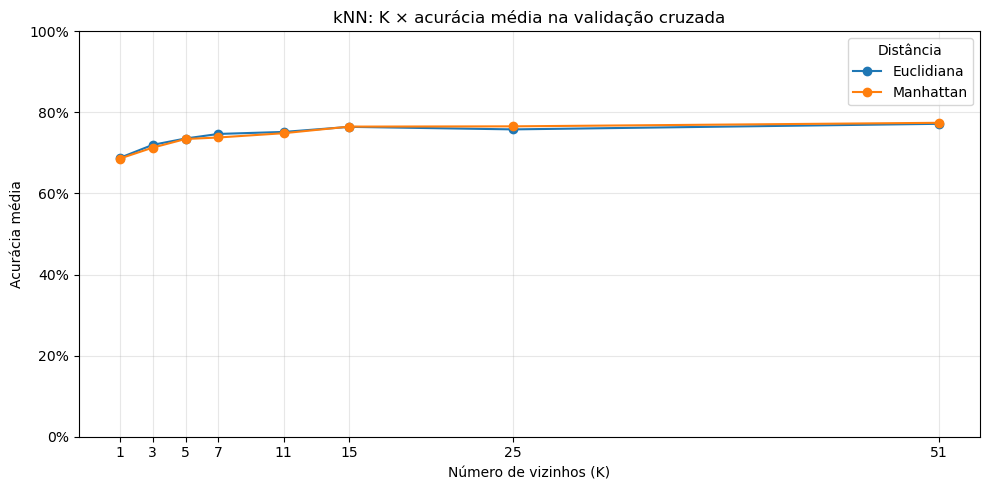

In [29]:
fig, ax = plt.subplots(figsize=(10, 5))

for distancia, cor in cores.items():

    # Selecionar uma distância e organizar os valores de K
    dados_grafico = (
        tabela_knn[tabela_knn["Distância"] == distancia]
        .sort_values("k")
    )

    # Desenhar uma linha com um ponto para cada K
    ax.plot(
        dados_grafico["k"],
        dados_grafico["Acurácia média"],
        marker="o",
        color=cor,
        label=distancia
    )

ax.set_title("kNN: K × acurácia média na validação cruzada")
ax.set_xlabel("Número de vizinhos (K)")
ax.set_ylabel("Acurácia média")

ax.set_xticks(valores_k)
ax.set_ylim(0, 1)
ax.yaxis.set_major_formatter(PercentFormatter(xmax=1))

ax.grid(alpha=0.3)
ax.legend(title="Distância")

fig.tight_layout()

# Salvar antes de mostrar
fig.savefig("knn_k_acuracia.png", dpi=300, bbox_inches="tight")

plt.show()

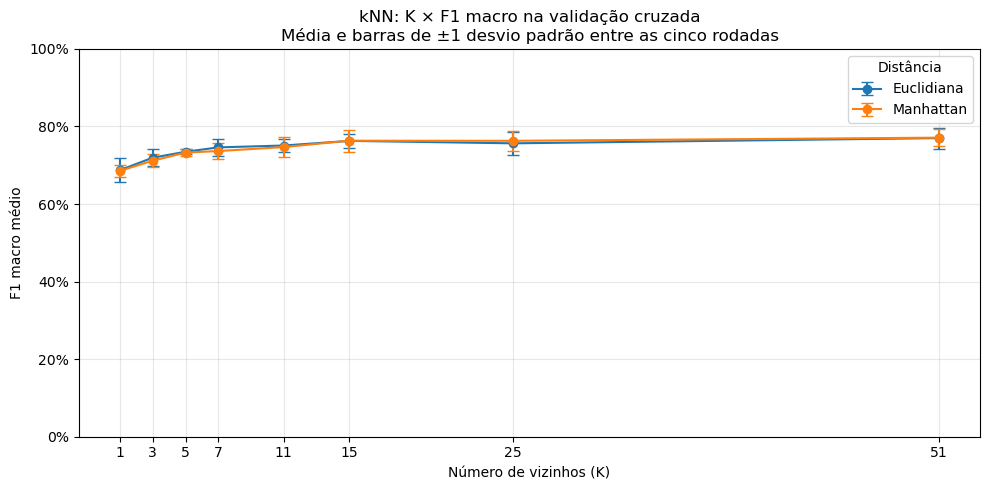

In [30]:
fig, ax = plt.subplots(figsize=(10, 5))

for distancia, cor in cores.items():

    dados_grafico = (
        tabela_knn[tabela_knn["Distância"] == distancia]
        .sort_values("k")
    )

    ax.errorbar(
        dados_grafico["k"],
        dados_grafico["F1 macro médio"],
        yerr=dados_grafico["Desvio padrão F1"],
        marker="o",
        linestyle="-",
        capsize=4,
        color=cor,
        label=distancia
    )

ax.set_title(
    "kNN: K × F1 macro na validação cruzada\n"
    "Média e barras de ±1 desvio padrão entre as cinco rodadas"
)

ax.set_xlabel("Número de vizinhos (K)")
ax.set_ylabel("F1 macro médio")

ax.set_xticks(valores_k)
ax.set_ylim(0, 1)
ax.yaxis.set_major_formatter(PercentFormatter(xmax=1))

ax.grid(alpha=0.3)
ax.legend(title="Distância")

fig.tight_layout()
fig.savefig("knn_k_f1_macro.png", dpi=300, bbox_inches="tight")

plt.show()

### 6.2 Análise dos resultados do kNN

Nos valores avaliados, aumentar o número de vizinhos melhorou
o desempenho médio em relação a K = 1. A melhora foi mais
acentuada até aproximadamente K = 15, seguida por ganhos menores
e pequenas oscilações.

As distâncias Euclidiana e Manhattan apresentaram resultados
próximos, sem superioridade de uma delas em todos os valores de K.

Visualmente, K = 51 apresentou as maiores médias. A configuração
será selecionada consultando o F1 macro médio da tabela, sem
arredondamento prévio.

As barras representam ±1 desvio padrão entre as cinco rodadas.
Elas descrevem a variação observada, mas não constituem um teste
de significância estatística.

As conclusões se restringem às configurações e divisões avaliadas.
O desempenho no conjunto de teste ainda não foi calculado.

In [31]:
# Localizar o maior F1 macro médio, usando os valores completos
indice_melhor = tabela_knn["F1 macro médio"].idxmax()
melhor_knn = tabela_knn.loc[indice_melhor]

melhor_k = int(melhor_knn["k"])
melhor_distancia = melhor_knn["Distância"]

print("Configuração selecionada por validação cruzada:")
print("K:", melhor_k)
print("Distância:", melhor_distancia)
print(f"Acurácia média: {melhor_knn['Acurácia média']:.2%}")
print(f"F1 macro médio: {melhor_knn['F1 macro médio']:.2%}")

Configuração selecionada por validação cruzada:
K: 51
Distância: Manhattan
Acurácia média: 77.44%
F1 macro médio: 77.12%


## 7. Primeiro modelo SVM

A Máquina de Vetores de Suporte (SVM) constrói uma fronteira
de decisão entre as classes. O treinamento considera a margem
de separação e as penalizações por violações dessa margem.

Os vetores de suporte são exemplos de treinamento que participam
da definição da fronteira de decisão.


### 7.1 Kernel RBF

Utilizaremos o kernel RBF, que permite construir fronteiras
não lineares no espaço dos atributos.

Sua expressão é:

$$
K(\mathbf{x}, \mathbf{v}) =
\exp\left(-\gamma \|\mathbf{x} - \mathbf{v}\|^2\right)
$$

Em que:

- $\mathbf{x}$ e $\mathbf{v}$ representam exemplos após o pré-processamento;
- $\|\mathbf{x} - \mathbf{v}\|^2$ é a distância Euclidiana ao quadrado;
- $\gamma$ controla a rapidez com que a similaridade diminui
  com a distância;
- $K$ representa a função kernel, não o número de vizinhos do kNN.

### 7.2 Configuração inicial

Começaremos com:

- kernel RBF;
- C = 1;
- gamma = 0.1.

C controla a penalização por violações da margem.
Gamma controla o alcance da similaridade no kernel RBF.

Esses valores são um ponto de partida, não uma configuração
já identificada como a melhor.

Usaremos o mesmo pré-processamento, as mesmas divisões de validação
cruzada e as mesmas métricas adotadas no kNN.

In [32]:
from sklearn.svm import SVC

svm_inicial = Pipeline(
    steps=[
        ("preprocessamento", clone(preprocessador)),
        (
            "modelo",
            SVC(
                kernel="rbf",
                C=1.0,
                gamma=0.1
            )
        )
    ]
)

print(svm_inicial)

Pipeline(steps=[('preprocessamento',
                 ColumnTransformer(transformers=[('numericas', StandardScaler(),
                                                  ['distancia_km',
                                                   'nivel_transito',
                                                   'intensidade_chuva',
                                                   'preparacao_pedido_min',
                                                   'prazo_prometido_min',
                                                   'paradas_adicionais',
                                                   'experiencia_anos']),
                                                 ('binarias', 'passthrough',
                                                  ['horario_pico',
                                                   'entregador_fixo']),
                                                 ('veiculo',
                                                  OneHotEncoder(handle_unknown='ignore',
            

In [33]:
# Ajustar o pipeline somente com os dados de treino
svm_inicial.fit(X_train, y_train)

# Acessar o classificador dentro do pipeline
classificador_svm = svm_inicial.named_steps["modelo"]

print("Primeiro SVM ajustado!")
print("Quantidade de entregas no treino:", len(X_train))
print(
    "Quantidade de atributos recebidos pelo SVM:",
    classificador_svm.n_features_in_
)

# Mostrar quantos vetores de suporte pertencem a cada classe
nomes_classes = {
    0: "Entrega atrasada",
    1: "Entrega no prazo"
}

suportes_por_classe = pd.DataFrame({
    "Classe": [
        nomes_classes[classe]
        for classe in classificador_svm.classes_
    ],
    "Vetores de suporte": classificador_svm.n_support_
})

display(suportes_por_classe)

print(
    "Total de vetores de suporte:",
    classificador_svm.n_support_.sum()
)

Primeiro SVM ajustado!
Quantidade de entregas no treino: 1600
Quantidade de atributos recebidos pelo SVM: 12


,Classe,Vetores de suporte
0,Entrega atrasada,417
1,Entrega no prazo,426


Total de vetores de suporte: 843


### 7.3 Avaliação inicial do SVM

Avaliaremos o SVM por validação cruzada estratificada em cinco
divisões, usando somente as 1.600 entregas do conjunto de treino.

Utilizaremos o mesmo objeto de divisão `cv` empregado no kNN,
permitindo comparar os algoritmos nas mesmas partições.

O pré-processamento será ajustado novamente dentro de cada rodada.

As métricas serão acurácia, precisão macro, recall macro e F1 macro.
O conjunto de teste continuará reservado para a avaliação final.

In [34]:
# Avaliar cópias do pipeline nas mesmas divisões usadas no kNN
avaliacao_svm = cross_validate(
    svm_inicial,
    X_train,
    y_train,
    cv=cv,
    scoring=metricas_cv
)

# Organizar os resultados de cada rodada
resultados_svm_inicial = pd.DataFrame({
    "Rodada": range(1, 6),
    "Acurácia": avaliacao_svm["test_acuracia"],
    "Precisão macro": avaliacao_svm["test_precisao_macro"],
    "Recall macro": avaliacao_svm["test_recall_macro"],
    "F1 macro": avaliacao_svm["test_f1_macro"]
})

display(resultados_svm_inicial.round(4))

# Calcular média e desvio padrão entre as rodadas
resumo_svm_inicial = (
    resultados_svm_inicial
    .drop(columns="Rodada")
    .agg(["mean", "std"])
    .rename(index={
        "mean": "Média",
        "std": "Desvio padrão"
    })
)

display(resumo_svm_inicial.round(4))

,Rodada,Acurácia,Precisão macro,Recall macro,F1 macro
0,1,0.7969,0.7969,0.7958,0.7962
1,2,0.7719,0.7726,0.7729,0.7719
2,3,0.7688,0.7684,0.7687,0.7685
3,4,0.7594,0.7593,0.7596,0.7593
4,5,0.8094,0.8093,0.8088,0.8090


,Acurácia,Precisão macro,Recall macro,F1 macro
Média,0.7812,0.7813,0.7812,0.7810
Desvio padrão,0.0210,0.0209,0.0204,0.0208


## 8. Comparação dos parâmetros do SVM com kernel RBF

Compararemos as combinações dos seguintes valores:

- C: 0.01, 0.1, 1, 10 e 100.
- Gamma: 0.001, 0.01, 0.1, 1 e 10.

Isso resulta em 25 configurações:

$$
5 \times 5 = 25
$$

C controla a penalização por violações da margem.
Gamma controla a rapidez com que a similaridade do kernel RBF
diminui com a distância entre exemplos.

Cada configuração será avaliada pelas mesmas cinco divisões
da validação cruzada estratificada utilizadas no kNN.

O pré-processamento será ajustado dentro de cada rodada.
As 400 entregas de teste permanecerão reservadas.

O critério principal de seleção será o F1 macro médio,
mantendo o mesmo critério adotado para o kNN.

In [35]:
valores_c = [0.01, 0.1, 1, 10, 100]
valores_gamma = [0.001, 0.01, 0.1, 1, 10]

# Reiniciar a lista a cada execução desta célula
resultados_svm = []

for c in valores_c:
    for gamma in valores_gamma:

        # Criar o pipeline para esta combinação
        pipeline_svm = Pipeline(
            steps=[
                ("preprocessamento", clone(preprocessador)),
                (
                    "modelo",
                    SVC(
                        kernel="rbf",
                        C=c,
                        gamma=gamma
                    )
                )
            ]
        )

        # Avaliar nas mesmas divisões utilizadas anteriormente
        avaliacao = cross_validate(
            pipeline_svm,
            X_train,
            y_train,
            cv=cv,
            scoring=metricas_cv,
            error_score="raise"
        )

        # Guardar as médias e a variação do F1
        resultados_svm.append({
            "C": c,
            "Gamma": gamma,
            "Acurácia média": avaliacao["test_acuracia"].mean(),
            "Precisão macro média": avaliacao["test_precisao_macro"].mean(),
            "Recall macro médio": avaliacao["test_recall_macro"].mean(),
            "F1 macro médio": avaliacao["test_f1_macro"].mean(),
            "Desvio padrão F1": (
                avaliacao["test_f1_macro"].std(ddof=1)
            )
        })

        print(f"Concluído: C={c}, gamma={gamma}")

Concluído: C=0.01, gamma=0.001
Concluído: C=0.01, gamma=0.01
Concluído: C=0.01, gamma=0.1
Concluído: C=0.01, gamma=1
Concluído: C=0.01, gamma=10
Concluído: C=0.1, gamma=0.001
Concluído: C=0.1, gamma=0.01
Concluído: C=0.1, gamma=0.1
Concluído: C=0.1, gamma=1
Concluído: C=0.1, gamma=10
Concluído: C=1, gamma=0.001
Concluído: C=1, gamma=0.01
Concluído: C=1, gamma=0.1
Concluído: C=1, gamma=1
Concluído: C=1, gamma=10
Concluído: C=10, gamma=0.001
Concluído: C=10, gamma=0.01
Concluído: C=10, gamma=0.1
Concluído: C=10, gamma=1
Concluído: C=10, gamma=10
Concluído: C=100, gamma=0.001
Concluído: C=100, gamma=0.01
Concluído: C=100, gamma=0.1
Concluído: C=100, gamma=1
Concluído: C=100, gamma=10


In [36]:
tabela_svm = pd.DataFrame(resultados_svm)

# Ordenar pelo maior F1 macro médio
tabela_svm = (
    tabela_svm
    .sort_values(
        by="F1 macro médio",
        ascending=False,
        kind="stable"
    )
    .reset_index(drop=True)
)

print("Quantidade de configurações:", len(tabela_svm))

display(tabela_svm.round(4))

Quantidade de configurações: 25


,C,Gamma,Acurácia média,Precisão macro média,Recall macro médio,F1 macro médio,Desvio padrão F1
0,10.00,0.010,0.7925,0.7928,0.7917,0.7919,0.0288
1,100.00,0.001,0.7906,0.7912,0.7897,0.7899,0.0217
2,0.10,0.100,0.7906,0.7912,0.7895,0.7898,0.0247
3,10.00,0.001,0.7900,0.7908,0.7888,0.7891,0.0245
4,1.00,0.001,0.7894,0.7907,0.7878,0.7883,0.0220
5,1.00,0.010,0.7888,0.7894,0.7876,0.7879,0.0264
6,0.10,0.010,0.7888,0.7903,0.7871,0.7876,0.0239
7,1.00,0.100,0.7812,0.7813,0.7812,0.7810,0.0208
8,100.00,0.010,0.7775,0.7776,0.7769,0.7770,0.0255
9,10.00,0.100,0.7619,0.7623,0.7614,0.7613,0.0144


In [37]:
indice_melhor_svm = tabela_svm["F1 macro médio"].idxmax()
melhor_svm = tabela_svm.loc[indice_melhor_svm]

melhor_c = float(melhor_svm["C"])
melhor_gamma = float(melhor_svm["Gamma"])

print("Configuração selecionada por validação cruzada:")
print("C:", melhor_c)
print("Gamma:", melhor_gamma)
print(f"Acurácia média: {melhor_svm['Acurácia média']:.2%}")
print(f"F1 macro médio: {melhor_svm['F1 macro médio']:.2%}")

Configuração selecionada por validação cruzada:
C: 10.0
Gamma: 0.01
Acurácia média: 79.25%
F1 macro médio: 79.19%


In [38]:
configuracao_inicial_svm = tabela_svm[
    (tabela_svm["C"] == 1.0)
    & (tabela_svm["Gamma"] == 0.1)
]

display(configuracao_inicial_svm.round(4))

,C,Gamma,Acurácia média,Precisão macro média,Recall macro médio,F1 macro médio,Desvio padrão F1
7,1.0,0.1,0.7812,0.7813,0.7812,0.781,0.0208


### 8.1 Influência de C e gamma no desempenho

Utilizaremos mapas de calor para visualizar as 25 configurações
do SVM com kernel RBF.

- Linhas: valores de C.
- Colunas: valores de gamma.
- Cada célula: média da métrica nas cinco rodadas de validação cruzada.

As cores e os valores escritos permitem comparar as configurações.

A seleção será baseada no F1 macro médio. A acurácia também será
apresentada para complementar a análise.

Todos os resultados são provenientes do conjunto de treino.
O conjunto de teste continua reservado.

In [39]:
# Organizar C nas linhas e gamma nas colunas
mapa_acuracia = tabela_svm.pivot(
    index="C",
    columns="Gamma",
    values="Acurácia média"
).reindex(index=valores_c, columns=valores_gamma)

mapa_f1 = tabela_svm.pivot(
    index="C",
    columns="Gamma",
    values="F1 macro médio"
).reindex(index=valores_c, columns=valores_gamma)

display(mapa_f1.round(4))

Gamma,0.001,0.010,0.100,1.000,10.000
C,,,,,
0.01,0.3421,0.3421,0.3771,0.3421,0.3421
0.10,0.3421,0.7876,0.7898,0.3421,0.3421
1.00,0.7883,0.7879,0.7810,0.7448,0.3444
10.00,0.7891,0.7919,0.7613,0.7375,0.3467
100.00,0.7899,0.7770,0.7188,0.7375,0.3467


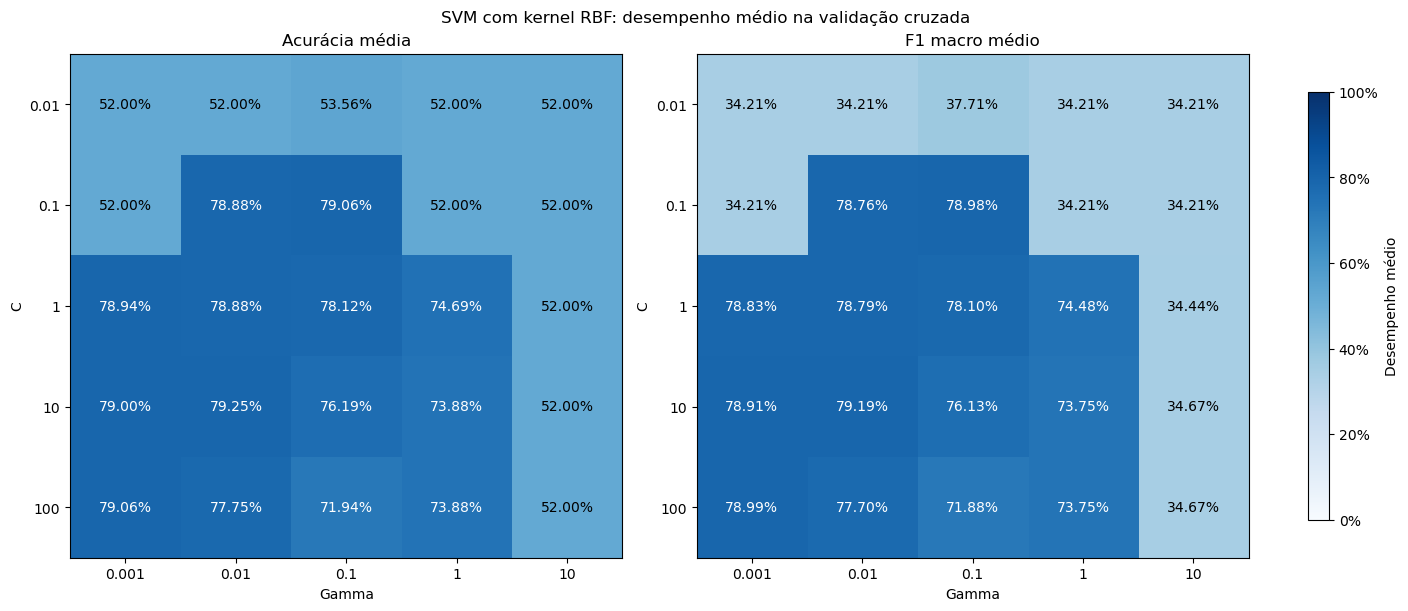

In [40]:
fig, eixos = plt.subplots(
    1, 2,
    figsize=(14, 6),
    constrained_layout=True
)

mapas = [
    (mapa_acuracia, "Acurácia média"),
    (mapa_f1, "F1 macro médio")
]

for ax, (matriz, titulo) in zip(eixos, mapas):

    imagem = ax.imshow(
        matriz.to_numpy(),
        cmap="Blues",
        vmin=0,
        vmax=1,
        aspect="auto"
    )

    # Identificar as linhas e colunas
    ax.set_xticks(range(len(valores_gamma)))
    ax.set_xticklabels([f"{g:g}" for g in valores_gamma])

    ax.set_yticks(range(len(valores_c)))
    ax.set_yticklabels([f"{c:g}" for c in valores_c])

    ax.set_xlabel("Gamma")
    ax.set_ylabel("C")
    ax.set_title(titulo)

    # Escrever o resultado dentro de cada célula
    for linha in range(matriz.shape[0]):
        for coluna in range(matriz.shape[1]):

            valor = matriz.iloc[linha, coluna]

            ax.text(
                coluna,
                linha,
                f"{valor:.2%}",
                ha="center",
                va="center",
                color="white" if valor >= 0.6 else "black"
            )

fig.suptitle(
    "SVM com kernel RBF: desempenho médio na validação cruzada"
)

# Escala de cores compartilhada pelos dois gráficos
barra = fig.colorbar(
    imagem,
    ax=eixos.tolist(),
    format=PercentFormatter(xmax=1),
    shrink=0.85
)

barra.set_label("Desempenho médio")

fig.savefig(
    "svm_c_gamma_mapas_calor.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### 8.2 Análise dos resultados do SVM

A configuração com maior F1 macro médio na validação cruzada
foi C = 10 e gamma = 0.01, com aproximadamente 79,19%.
Sua acurácia média foi de 79,25%.

As melhores configurações apresentaram resultados próximos.
Por isso, a maior média observada não comprova superioridade
estatística em relação às demais.

Com gamma = 10, todas as configurações apresentaram acurácia
de aproximadamente 52%, indicando desempenho baixo.
Várias configurações apresentaram resultados compatíveis
com a previsão predominante da classe majoritária.

Os resultados mostram que C e gamma devem ser avaliados
conjuntamente. Aumentar seus valores não garante uma melhora.

A configuração foi selecionada somente pela validação cruzada
no treino. O conjunto de teste será utilizado na próxima etapa.

## 9. Avaliação final no conjunto de teste

Após selecionar os parâmetros por validação cruzada,
ajustaremos cada modelo nas 1.600 entregas de treinamento.

A avaliação final utilizará as mesmas 400 entregas de teste
para os dois modelos.

O pré-processamento será aprendido exclusivamente no treino
e aplicado ao teste pelo pipeline.

Compararemos acurácia, precisão macro, recall macro e F1 macro.
Também apresentaremos matrizes de confusão.

Os resultados de teste não serão usados para reajustar os
hiperparâmetros.

In [41]:
# Recuperar a configuração com maior F1 macro médio de cada tabela
melhor_knn = tabela_knn.loc[tabela_knn["F1 macro médio"].idxmax()]
melhor_svm = tabela_svm.loc[tabela_svm["F1 macro médio"].idxmax()]

melhor_k = int(melhor_knn["k"])

# Converter o nome da distância para o formato da biblioteca
melhor_metrica_knn = {
    "Euclidiana": "euclidean",
    "Manhattan": "manhattan"
}[melhor_knn["Distância"]]

melhor_c = float(melhor_svm["C"])
melhor_gamma = float(melhor_svm["Gamma"])

print("kNN selecionado:")
print("K =", melhor_k)
print("Distância =", melhor_knn["Distância"])

print("\nSVM selecionado:")
print("C =", melhor_c)
print("Gamma =", melhor_gamma)

kNN selecionado:
K = 51
Distância = Manhattan

SVM selecionado:
C = 10.0
Gamma = 0.01


In [42]:
knn_final = Pipeline(
    steps=[
        ("preprocessamento", clone(preprocessador)),
        (
            "modelo",
            KNeighborsClassifier(
                n_neighbors=melhor_k,
                metric=melhor_metrica_knn,
                weights="uniform"
            )
        )
    ]
)

svm_final = Pipeline(
    steps=[
        ("preprocessamento", clone(preprocessador)),
        (
            "modelo",
            SVC(
                kernel="rbf",
                C=melhor_c,
                gamma=melhor_gamma
            )
        )
    ]
)

# Ajustar os dois modelos usando todo o conjunto de treino
knn_final.fit(X_train, y_train)
svm_final.fit(X_train, y_train)

# Prever as classes das entregas de teste
pred_knn = knn_final.predict(X_test)
pred_svm = svm_final.predict(X_test)

print("Quantidade de previsões do kNN:", len(pred_knn))
print("Quantidade de previsões do SVM:", len(pred_svm))

Quantidade de previsões do kNN: 400
Quantidade de previsões do SVM: 400


In [43]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

resultados_teste = []

for nome, previsoes in [
    ("kNN", pred_knn),
    ("SVM RBF", pred_svm)
]:
    resultados_teste.append({
        "Modelo": nome,
        "Acurácia": accuracy_score(y_test, previsoes),
        "Precisão macro": precision_score(
            y_test, previsoes,
            average="macro",
            zero_division=0
        ),
        "Recall macro": recall_score(
            y_test, previsoes,
            average="macro",
            zero_division=0
        ),
        "F1 macro": f1_score(
            y_test, previsoes,
            average="macro",
            zero_division=0
        )
    })

tabela_teste = pd.DataFrame(resultados_teste).set_index("Modelo")

display(tabela_teste.style.format("{:.2%}"))

# Salvar os resultados para uso posterior no relatório
tabela_teste.to_csv(
    "comparacao_modelos_teste.csv",
    encoding="utf-8-sig"
)

,Acurácia,Precisão macro,Recall macro,F1 macro
Modelo,,,,
kNN,82.25%,82.35%,82.11%,82.17%
SVM RBF,82.50%,82.59%,82.61%,82.50%


### 9.1 Matrizes de confusão

As matrizes de confusão detalham os acertos e erros dos modelos
nas 400 entregas do conjunto de teste.

As linhas representam as classes reais e as colunas representam
as classes previstas.

Considerando a classe positiva como 1 — entrega no prazo:

- Verdadeiro negativo (VN): entrega atrasada prevista como atrasada.
- Falso positivo (FP): entrega atrasada prevista como no prazo.
- Falso negativo (FN): entrega no prazo prevista como atrasada.
- Verdadeiro positivo (VP): entrega no prazo prevista como no prazo.

A acurácia pode ser calculada por:

$$
\mathrm{Acurácia} =
\frac{VP + VN}{VP + VN + FP + FN}
$$

Um falso positivo representa uma previsão de pontualidade que
não se confirmou. Um falso negativo representa um alerta de
atraso para uma entrega que chegou no prazo.

A importância de cada erro depende dos custos e objetivos da
operação. Não foi definido um custo específico para esses erros
neste experimento.

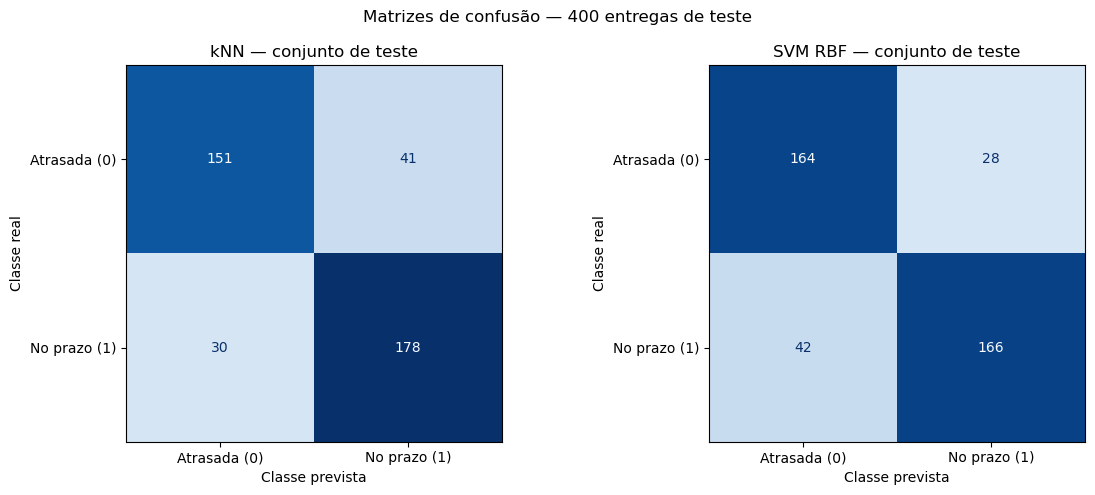

In [44]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# Calcular as matrizes mantendo a ordem: classe 0, depois classe 1
matriz_knn = confusion_matrix(
    y_test,
    pred_knn,
    labels=[0, 1]
)

matriz_svm = confusion_matrix(
    y_test,
    pred_svm,
    labels=[0, 1]
)

# Criar dois gráficos lado a lado
fig, eixos = plt.subplots(1, 2, figsize=(12, 5))

rotulos = ["Atrasada (0)", "No prazo (1)"]

# Usar a mesma escala de cores para os dois modelos
maior_contagem = max(matriz_knn.max(), matriz_svm.max())

for ax, matriz, nome in [
    (eixos[0], matriz_knn, "kNN"),
    (eixos[1], matriz_svm, "SVM RBF")
]:
    exibicao = ConfusionMatrixDisplay(
        confusion_matrix=matriz,
        display_labels=rotulos
    )

    exibicao.plot(
        ax=ax,
        cmap="Blues",
        values_format="d",
        colorbar=False,
        im_kw={"vmin": 0, "vmax": maior_contagem}
    )

    ax.set_title(f"{nome} — conjunto de teste")
    ax.set_xlabel("Classe prevista")
    ax.set_ylabel("Classe real")

fig.suptitle("Matrizes de confusão — 400 entregas de teste")
fig.tight_layout()

fig.savefig(
    "matrizes_confusao_teste.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [45]:
resumo_erros = []

for nome, matriz in [
    ("kNN", matriz_knn),
    ("SVM RBF", matriz_svm)
]:
    vn, fp, fn, vp = matriz.ravel()

    resumo_erros.append({
        "Modelo": nome,
        "Atrasos identificados (VN)": vn,
        "Atrasos previstos como no prazo (FP)": fp,
        "No prazo previstos como atraso (FN)": fn,
        "Pontualidade identificada (VP)": vp,
        "Total de erros": fp + fn
    })

tabela_erros = pd.DataFrame(resumo_erros).set_index("Modelo")

display(tabela_erros)

tabela_erros.to_csv(
    "tipos_erros_teste.csv",
    encoding="utf-8-sig"
)

,Atrasos identificados (VN),Atrasos previstos como no prazo (FP),No prazo previstos como atraso (FN),Pontualidade identificada (VP),Total de erros
Modelo,,,,,
kNN,151,41,30,178,71
SVM RBF,164,28,42,166,70


### 9.2 Análise das matrizes de confusão

O conjunto de teste contém 192 entregas atrasadas e 208 entregas
no prazo, totalizando 400 registros.

O kNN classificou corretamente 329 entregas, com acurácia de 82,25%.
O SVM classificou corretamente 330, com acurácia de 82,50%.

Apesar da proximidade na acurácia, os modelos apresentaram
diferenças nos tipos de erro.

O SVM identificou 164 dos 192 atrasos (85,42%), enquanto o kNN
identificou 151 (78,65%).

Por outro lado, o kNN identificou corretamente 178 das 208 entregas
pontuais (85,58%), enquanto o SVM identificou 166 (79,81%).

Assim, o SVM apresentou maior capacidade de identificar atrasos,
mas gerou mais alertas de atraso para entregas pontuais:
42, contra 30 do kNN.

A escolha operacional depende da importância atribuída a cada
tipo de erro. Como esses custos não foram definidos, a conclusão
se limita ao desempenho observado neste conjunto de teste.

A classe positiva continua sendo 1 — entrega no prazo.
Portanto, a identificação dos atrasos corresponde ao recall
da classe 0, também chamado de especificidade quando a classe 1
é considerada positiva.

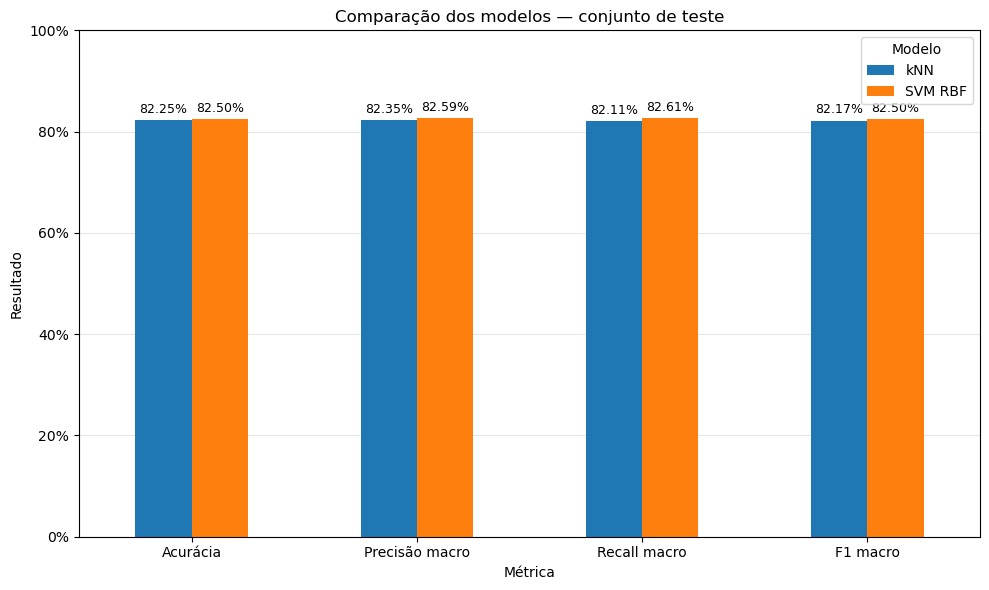

In [46]:
# Transpor a tabela: métricas nas linhas e modelos nas colunas
ax = tabela_teste.T.plot(
    kind="bar",
    figsize=(10, 6),
    color=["tab:blue", "tab:orange"],
    rot=0
)

ax.set_title("Comparação dos modelos — conjunto de teste")
ax.set_xlabel("Métrica")
ax.set_ylabel("Resultado")

ax.set_ylim(0, 1)
ax.yaxis.set_major_formatter(PercentFormatter(xmax=1))
ax.legend(title="Modelo")
ax.grid(axis="y", alpha=0.3)
ax.set_axisbelow(True)

# Mostrar os valores acima das barras
for conjunto_barras in ax.containers:
    ax.bar_label(
        conjunto_barras,
        labels=[
            f"{barra.get_height():.2%}"
            for barra in conjunto_barras
        ],
        padding=3,
        fontsize=9
    )

fig = ax.get_figure()
fig.tight_layout()

fig.savefig(
    "comparacao_metricas_teste.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()